In [2]:
import warnings
warnings.filterwarnings('ignore')

import sys
import pandas as pd
import numpy as np
from scipy import stats
from matplotlib import style
import seaborn as sns
from pathlib import Path
from matplotlib import pyplot as plt
import statsmodels.formula.api as smf
import graphviz as gr

style.use("fivethirtyeight")

In [3]:
cwd = Path.cwd()
project_root = cwd.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print("Done!")

Done!


In [4]:
data = pd.read_csv(project_root / 'data' / 'collections_email.csv')
data.head()

,payments,email,opened,agreement,credit_limit,risk_score
0,740,1,1.0,0.0,2348.495260,0.666752
1,580,1,1.0,1.0,334.111969,0.207395
2,600,1,1.0,1.0,1360.660722,0.550479
3,770,0,0.0,0.0,1531.828576,0.560488
4,660,0,0.0,0.0,979.855647,0.455140


In [5]:
data.shape

(5000, 6)

In [7]:
print(f'Difference in Means: {data.loc[data['email'] == 1.0]['payments'].mean() - data.loc[data['email'] == 0.0]['payments'].mean()}')

Difference in Means: -0.6202804021329484


In [8]:
model = smf.ols('payments ~ email', data=data).fit()
model.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,669.9764,2.061,325.116,0.000,665.937,674.016
email,-0.6203,2.941,-0.211,0.833,-6.387,5.146


In [9]:
data.columns

Index(['payments', 'email', 'opened', 'agreement', 'credit_limit',
       'risk_score'],
      dtype='str')

In [11]:
model_email = smf.ols('email ~ credit_limit + risk_score', data=data).fit()
model_payments = smf.ols('payments ~ credit_limit + risk_score', data=data).fit()

residuals = pd.DataFrame(dict(res_payments=model_payments.resid, res_email=model_email.resid))

In [15]:
model_treatment = smf.ols('res_payments ~ res_email', data=residuals).fit()

In [16]:
print("Payments Variance", np.var(data["payments"]))
print("Payments Residual Variance", np.var(residuals["res_payments"]))

print("Email Variance", np.var(data["email"]))
print("Email Residual Variance", np.var(residuals["res_email"]))

model_treatment.summary().tables[1]

Payments Variance 10807.612416
Payments Residual Variance 5652.453558466208
Email Variance 0.24991536
Email Residual Variance 0.24918421069820032


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,2.07e-13,1.063,1.95e-13,1.000,-2.084,2.084
res_email,4.4304,2.129,2.080,0.038,0.256,8.605


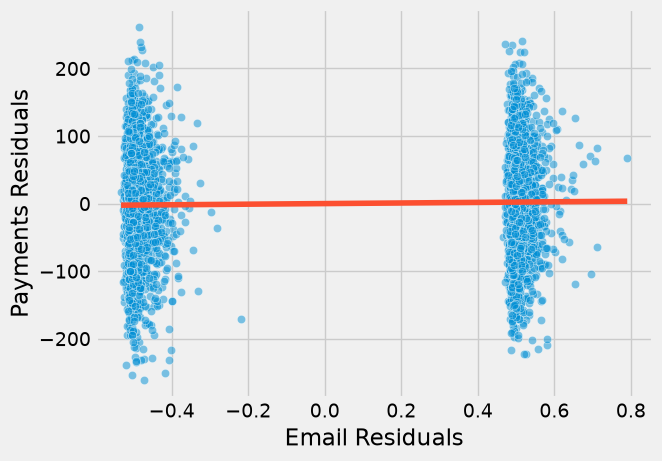

In [18]:
sns.scatterplot(
    x="res_email",
    y="res_payments",
    data=residuals,
    alpha=0.5
)

x = np.linspace(
    residuals["res_email"].min(),
    residuals["res_email"].max(),
    100
)

y = model_treatment.params.iloc[0] + model_treatment.params.iloc[1] * x

plt.plot(x, y, color="C1")

plt.xlabel("Email Residuals")
plt.ylabel("Payments Residuals")
plt.show()

In [19]:
model_2 = smf.ols('payments ~ email + credit_limit + risk_score', data=data).fit()
model_2.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,490.8653,9.715,50.527,0.000,471.820,509.911
email,4.4304,2.130,2.080,0.038,0.255,8.606
credit_limit,0.1511,0.008,18.833,0.000,0.135,0.167
risk_score,-8.0516,38.424,-0.210,0.834,-83.379,67.276
